# 电信客户流失：清洗、探索与模型评估

目标：识别值得调查的流失细分群，并比较三种模型的识别效果。流失率 = 流失人数 / 组内人数。观察到的关联不代表因果关系。

从项目根目录或 notebooks 目录运行全部单元；输出写入 data/processed 和 reports。模型结果仅在实际运行后产生。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'data/raw/Telco-Customer-Churn.csv').exists() else Path.cwd().parent
RAW = ROOT / 'data/raw/Telco-Customer-Churn.csv'
FIG = ROOT / 'reports/figures'
OUT = ROOT / 'reports'
PROCESSED = ROOT / 'data/processed'
for p in (FIG, OUT, PROCESSED):
    p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
raw = pd.read_csv(RAW)
print(f'Customers: {len(raw):,}; columns: {raw.shape[1]}')
display(raw.head())

Customers: 7,043; columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. 数据质量与清洗

去除字符串首尾空格，空白转缺失，TotalCharges 转数值。保留缺失值，后续仅在训练集拟合插补器；不删除客户，也不将未知金额直接填零。

In [2]:
df = raw.copy()
for col in df.select_dtypes(include='object'):
    df[col] = df[col].str.strip().replace('', np.nan)
original_total = df['TotalCharges'].copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Duplicate full rows:', df.duplicated().sum())
print('Missing customer IDs:', df.customerID.isna().sum())
print('Duplicate customer IDs:', df.customerID.duplicated().sum())
print('Invalid nonblank TotalCharges:', (original_total.notna() & df.TotalCharges.isna()).sum())
display(df.isna().sum().loc[lambda s: s > 0].rename('missing'))
display(df.loc[df.TotalCharges.isna(), ['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])
assert df.customerID.notna().all() and df.customerID.is_unique
assert df.Churn.isin(['Yes', 'No']).all()
df.to_csv(PROCESSED / 'telco_cleaned.csv', index=False)

Duplicate full rows: 0
Missing customer IDs: 0
Duplicate customer IDs: 0
Invalid nonblank TotalCharges: 0


C:\Users\13557\AppData\Local\Temp\ipykernel_37924\2152108714.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object'):


TotalCharges    11
Name: missing, dtype: int64

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


## 2. 探索性分析

展示整体基线、分组人数与流失率；分组可能相互重叠，不能直接归因。

Overall churn: 1,869 / 7,043 = 26.5%


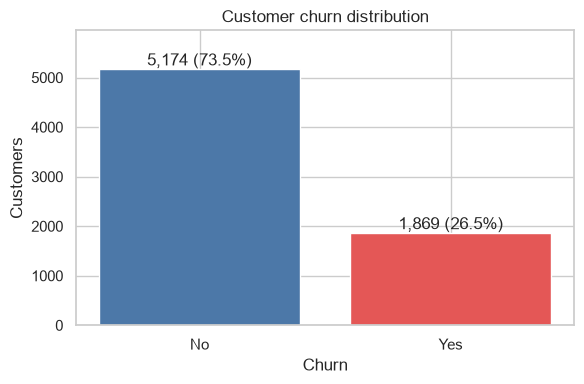

In [3]:
counts = df.Churn.value_counts().reindex(['No', 'Yes'], fill_value=0)
print(f'Overall churn: {counts.Yes:,} / {len(df):,} = {counts.Yes/len(df):.1%}')
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index, counts.values, color=['#4c78a8', '#e45756'])
for i, n in enumerate(counts):
    ax.text(i, n, f'{n:,} ({n/len(df):.1%})', ha='center', va='bottom')
ax.set(title='Customer churn distribution', xlabel='Churn', ylabel='Customers', ylim=(0, counts.max()*1.15))
fig.tight_layout(); fig.savefig(FIG / '01_churn_distribution.png', dpi=160); plt.show()


Contract


,customers,churned,churn_rate
Contract,,,
Month-to-month,3875,1655,42.7%
One year,1473,166,11.3%
Two year,1695,48,2.8%



InternetService


,customers,churned,churn_rate
InternetService,,,
Fiber optic,3096,1297,41.9%
DSL,2421,459,19.0%
No,1526,113,7.4%



PaymentMethod


,customers,churned,churn_rate
PaymentMethod,,,
Electronic check,2365,1071,45.3%
Mailed check,1612,308,19.1%
Bank transfer (automatic),1544,258,16.7%
Credit card (automatic),1522,232,15.2%


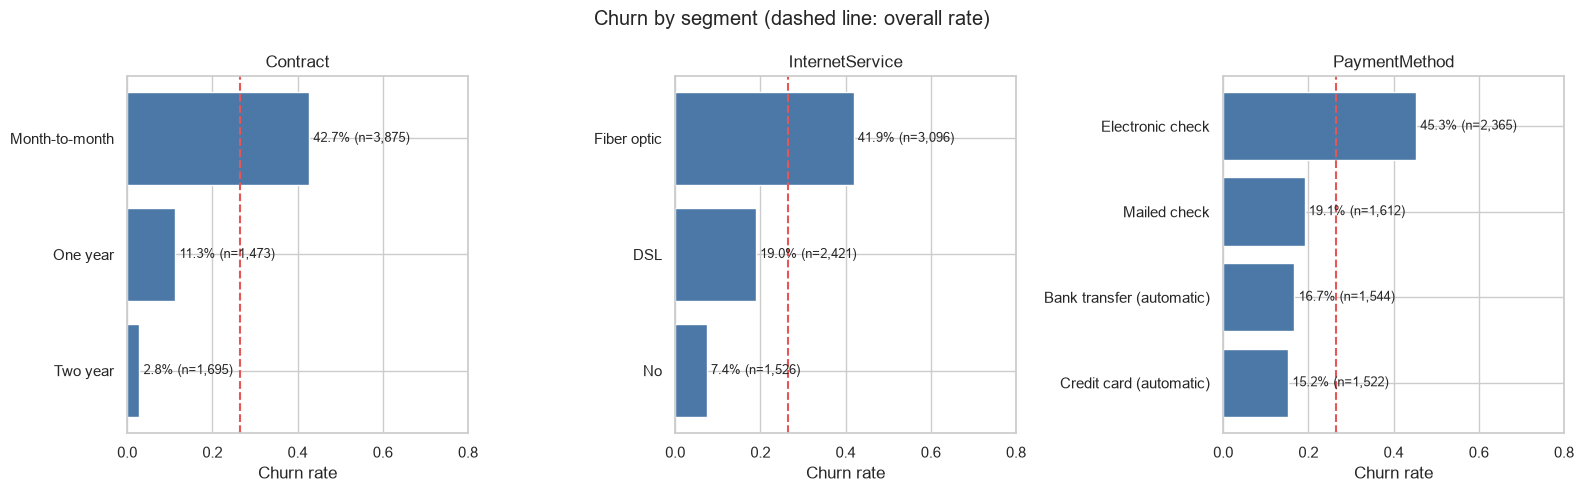

In [4]:
def segment_table(column):
    result = df.groupby(column, observed=True, dropna=False).agg(customers=('Churn', 'size'), churned=('Churn', lambda x: x.eq('Yes').sum()))
    result['churn_rate'] = result.churned / result.customers
    return result.sort_values('churn_rate', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ['Contract', 'InternetService', 'PaymentMethod']):
    t = segment_table(col)
    print('\n' + col); display(t.style.format({'churn_rate': '{:.1%}'}))
    ax.barh(range(len(t)), t.churn_rate, color='#4c78a8')
    ax.set_yticks(range(len(t)), labels=t.index.astype(str)); ax.invert_yaxis()
    for i, (rate, n) in enumerate(zip(t.churn_rate, t.customers)):
        ax.text(rate + .01, i, f'{rate:.1%} (n={n:,})', va='center', fontsize=9)
    ax.axvline(df.Churn.eq('Yes').mean(), color='#e45756', linestyle='--')
    ax.set(xlim=(0, .8), title=col, xlabel='Churn rate')
fig.suptitle('Churn by segment (dashed line: overall rate)')
fig.tight_layout(); fig.savefig(FIG / '02_segment_churn.png', dpi=160, bbox_inches='tight'); plt.show()

,customers,churned,churn_rate
tenure_group,,,
0-12,2186,1037,47.4%
13-24,1024,294,28.7%
25-48,1594,325,20.4%
49-72,2239,213,9.5%


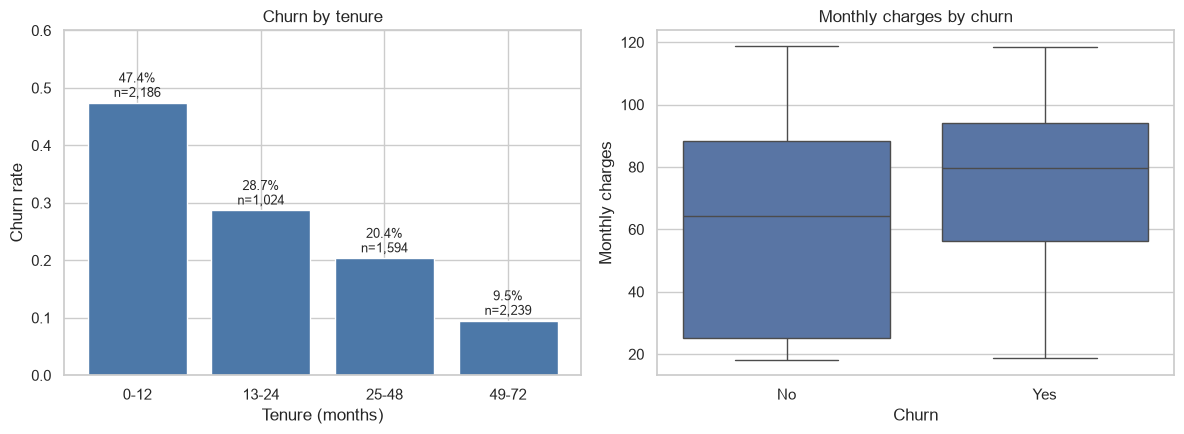

In [5]:
tenure_group = pd.cut(df.tenure, bins=[-1, 12, 24, 48, 72], labels=['0-12', '13-24', '25-48', '49-72'])
tenure_table = df.assign(tenure_group=tenure_group).groupby('tenure_group', observed=True).agg(customers=('Churn', 'size'), churned=('Churn', lambda x: x.eq('Yes').sum()))
tenure_table['churn_rate'] = tenure_table.churned / tenure_table.customers
display(tenure_table.style.format({'churn_rate': '{:.1%}'}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(tenure_table.index.astype(str), tenure_table.churn_rate, color='#4c78a8')
for i, (rate, n) in enumerate(zip(tenure_table.churn_rate, tenure_table.customers)):
    axes[0].text(i, rate + .01, f'{rate:.1%}\nn={n:,}', ha='center', fontsize=9)
axes[0].set(title='Churn by tenure', xlabel='Tenure (months)', ylabel='Churn rate', ylim=(0, .6))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', order=['No', 'Yes'], showfliers=False, ax=axes[1])
axes[1].set(title='Monthly charges by churn', xlabel='Churn', ylabel='Monthly charges')
fig.tight_layout(); fig.savefig(FIG / '03_tenure_charges.png', dpi=160); plt.show()

## 3. 公平模型比较

固定随机种子，按标签分层划分 60% 训练、20% 验证、20% 测试。三种模型使用相同划分和训练集拟合的预处理；类别独热编码，数值中位数插补并标准化。排除客户 ID。验证集只用于选择以 F1 为目标的阈值，测试集只做最终评估。无调参，比较默认模型而非声称最优。测试集是静态随机切分，不能替代时间外验证。

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve, roc_curve,
    precision_score, recall_score, f1_score, confusion_matrix, classification_report)
from xgboost import XGBClassifier

X = df.drop(columns=['customerID', 'Churn'])
y = df.Churn.eq('Yes').astype(int)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=.4, stratify=y, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_temp, y_temp, test_size=.5, stratify=y_temp, random_state=42)
print('Train / validation / test:', len(X_train), len(X_valid), len(X_test))
print('Churn rates:', *(f'{v.mean():.1%}' for v in [y_train, y_valid, y_test]))
num = X.select_dtypes(include='number').columns.tolist()
cat = X.select_dtypes(exclude='number').columns.tolist()
preprocess = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num),
    ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat)
])
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, random_state=42, n_jobs=-1, eval_metric='logloss')
}

Train / validation / test: 4225 1409 1409
Churn rates: 26.5% 26.5% 26.5%


In [7]:
results, fitted, probabilities = [], {}, {}
for name, model in models.items():
    pipe = Pipeline([('preprocess', preprocess), ('model', model)])
    pipe.fit(X_train, y_train)
    valid_prob = pipe.predict_proba(X_valid)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_valid, valid_prob)
    scores = 2 * precision[:-1] * recall[:-1] / np.maximum(precision[:-1] + recall[:-1], 1e-12)
    threshold = thresholds[np.argmax(scores)]
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    results.append({'model': name, 'validation_threshold': threshold, 'roc_auc': roc_auc_score(y_test, prob),
                    'pr_auc': average_precision_score(y_test, prob), 'precision': precision_score(y_test, pred, zero_division=0),
                    'recall': recall_score(y_test, pred, zero_division=0), 'f1': f1_score(y_test, pred, zero_division=0),
                    'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp, 'contacted': int(pred.sum())})
    fitted[name], probabilities[name] = pipe, prob
metrics = pd.DataFrame(results).set_index('model').sort_values('pr_auc', ascending=False)
display(metrics.round(3))
metrics.to_csv(OUT / 'model_comparison.csv')
print('PR-AUC is average precision; threshold is chosen on validation F1, not on the test set.')

,validation_threshold,roc_auc,pr_auc,precision,recall,f1,tn,fp,fn,tp,contacted
model,,,,,,,,,,,
Logistic Regression,0.495,0.832,0.622,0.614,0.532,0.570,910,125,175,199,324
Random Forest,0.321,0.806,0.591,0.521,0.698,0.597,795,240,113,261,501
XGBoost,0.170,0.786,0.558,0.484,0.676,0.564,765,270,121,253,523


PR-AUC is average precision; threshold is chosen on validation F1, not on the test set.


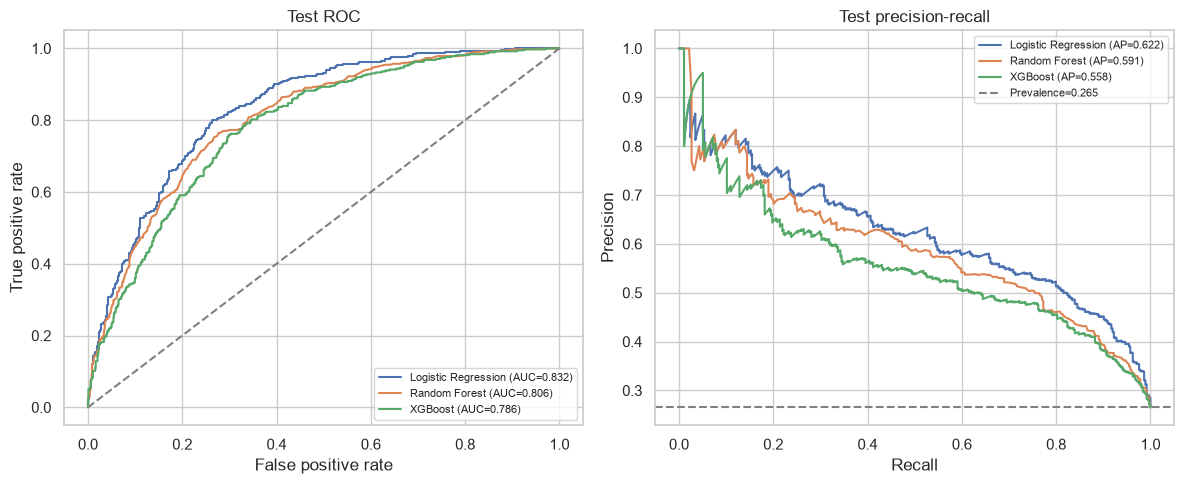

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    p, r, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, prob):.3f})')
    axes[1].plot(r, p, label=f'{name} (AP={average_precision_score(y_test, prob):.3f})')
axes[0].plot([0, 1], [0, 1], '--', color='gray'); axes[0].set(title='Test ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', label=f'Prevalence={y_test.mean():.3f}')
axes[1].set(title='Test precision-recall', xlabel='Recall', ylabel='Precision')
for ax in axes: ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / '04_model_curves.png', dpi=160); plt.show()

## 4. 业务应用与限制

- 根据测试集精确率、召回率、联系人数和混淆矩阵评估可执行性；F1 阈值是演示，不代表业务最优。
- 在已知触达预算、每次触达成本、客户价值与干预成功率后，利用验证集选择阈值并开展随机对照试验。高风险不等于可被挽回。
- 静态数据缺少明确预测时点、观察窗口及成本；正式部署前需核验所有特征在预测时可用，采用时间切分并检查漂移与公平性。